<a href="https://colab.research.google.com/github/Riccardo-27/DL-Quantum/blob/dev-ernesto/notebooks/05_inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 – Benchmark Finale (Table 1), 5-Fold Cross-Validation, Sintesi Sfide 1–2–3 e Demo Live sul Test Set

**Ruolo nella pipeline incrementale:** questo notebook conclusivo aggrega tutti i risultati prodotti dai 4 modelli della progressione (**$M_1, M_2$** da `03_rnn.ipynb` e **$M_3, M_4$** da `04_transformer.ipynb`) senza riaddestrare le griglie di iperparametri, e fornisce la **Demo Live di Inferenza** per l'esame orale:

1. **Sezione 1 – Aggregazione Log e `Table 1` Ufficiale**: unisce i log multi-autore (`results_log_*.csv`) e costruisce la **Table 1** in formato *Project Proposal* (RNN vs Transformer $\times$ `HP1..3` $\times$ `short, long`), con migliori risultati in grassetto e intervalli di confidenza al 95% ($t$ di Student su 3 seed).
2. **Sezione 2 – 5-Fold Cross-Validation per Traiettoria ($k=5$)**: valida la robustezza rispetto alla partizione delle 340 traiettorie di sviluppo (`train + val`, mantenendo cieco il Test Set) per i due vincitori di famiglia (**$M_1$ `HP1`** vs **$M_3$ `HP3`**), con caching istantaneo in `results/kfold_cv_results.csv`.
3. **Sezione 3 – Quadro Unificato delle Sfide 1, 2 e 3**: confronto diretto RNN vs Transformer sullo scaling della finestra $T_{in} \in \{5, 10, 20, 40\}$ (**Sfida 1**) e sulla Super-Risoluzione temporale $\times 2$ (**Sfida 2**).
4. **Sezione 4 – Inferenza Live da Checkpoint `.keras` sul Test Set Cieco**: ricarica istantaneamente `best_rnn_model.keras` e `best_transformer_model.keras` senza retraining, verifica la positività quantistica $P(s_i, s_j) \ge 0$ sulle 60 traiettorie di Test e visualizza le previsioni a 40 step in `< 1 s` per la prova orale.

## 0. Setup dell'Ambiente e Sincronizzazione Git

Rilevamento automatico dell'ambiente (Colab vs locale), configurazione del branch tramite Secret Colab (`GIT_E_TOKEN` $\to$ `dev-ernesto`, `GIT_R_TOKEN` $\to$ `dev-riccardo`) e determinismo numerico (`SEED = 42`).

In [1]:
# =============================================================================
# 0. Setup Ambiente, Rilevamento Autore da Segreto Colab e Sincronizzazione Git
# =============================================================================
import os
import sys
import time
import warnings
from pathlib import Path

# Filtro per mantenere l'output pulito durante la demo dell'esame orale
warnings.filterwarnings("ignore", message=".*softmax over axis 3.*")
warnings.filterwarnings("ignore", category=UserWarning)

IN_COLAB = "google.colab" in sys.modules

AUTHOR = None
CURRENT_BRANCH = None
GIT_TOKEN = None
AUTHOR_NAME = None
AUTHOR_EMAIL = None

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")

    DRIVE_REPO = Path("/content/drive/MyDrive/DL-Quantum")
    LOCAL_REPO = Path("/content/DL-Quantum")

    if (DRIVE_REPO / "src" / "seeding.py").exists():
        REPO_PATH = DRIVE_REPO
    elif (LOCAL_REPO / "src" / "seeding.py").exists():
        REPO_PATH = LOCAL_REPO
    elif DRIVE_REPO.exists():
        !git -C /content/drive/MyDrive/DL-Quantum fetch origin
        REPO_PATH = DRIVE_REPO
    else:
        print("Clonazione automatica del repository su Google Drive...")
        !git clone https://github.com/Riccardo-27/DL-Quantum.git /content/drive/MyDrive/DL-Quantum
        REPO_PATH = DRIVE_REPO

    try:
        GIT_TOKEN = userdata.get("GIT_E_TOKEN")
        if GIT_TOKEN:
            AUTHOR = "ernesto"
            CURRENT_BRANCH = "dev-ernesto"
            AUTHOR_NAME = "Ernesto Gligora"
            AUTHOR_EMAIL = "ernestogligora2003@gmail.com"
    except Exception:
        pass

    if not GIT_TOKEN:
        try:
            GIT_TOKEN = userdata.get("GIT_R_TOKEN")
            if GIT_TOKEN:
                AUTHOR = "riccardo"
                CURRENT_BRANCH = "dev-riccardo"
                AUTHOR_NAME = "Riccardo"
                AUTHOR_EMAIL = "lavoratoriccardo@gmail.com"
        except Exception:
            pass

    if not GIT_TOKEN:
        for k in ("GH_TOKEN", "GITHUB_TOKEN"):
            try:
                t = userdata.get(k)
                if t:
                    GIT_TOKEN = t
                    break
            except Exception:
                pass
else:
    REPO_PATH = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

if not CURRENT_BRANCH:
    b_check = !git -C "{REPO_PATH}" branch --show-current
    CURRENT_BRANCH = b_check[0].strip() if b_check and b_check[0].strip() else "dev-ernesto"

if not AUTHOR:
    if "riccardo" in CURRENT_BRANCH.lower():
        AUTHOR = "riccardo"
        AUTHOR_NAME = "Riccardo"
        AUTHOR_EMAIL = "lavoratoriccardo@gmail.com"
    else:
        AUTHOR = "ernesto"
        AUTHOR_NAME = "Ernesto Gligora"
        AUTHOR_EMAIL = "ernestogligora2003@gmail.com"

if IN_COLAB:
    print(f"Allineamento automatico sul branch '{CURRENT_BRANCH}' per {AUTHOR_NAME}...")
    !git -C "{REPO_PATH}" config user.name "{AUTHOR_NAME}"
    !git -C "{REPO_PATH}" config user.email "{AUTHOR_EMAIL}"
    !git -C "{REPO_PATH}" fetch origin
    !git -C "{REPO_PATH}" checkout -f {CURRENT_BRANCH}
    !git -C "{REPO_PATH}" pull --rebase --autostash origin {CURRENT_BRANCH}

os.environ["DLQ_AUTHOR"] = AUTHOR
os.environ["DLQ_ROOT"] = str(REPO_PATH)

if str(REPO_PATH) not in sys.path:
    sys.path.insert(0, str(REPO_PATH))

from src.seeding import set_seeds
SEED = 42
set_seeds(SEED)

try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
except ImportError:
    print("TensorFlow non rilevato nell'ambiente locale")

print(f"\n✔ Ambiente inizializzato! Autore: {AUTHOR_NAME} | Branch: {CURRENT_BRANCH} | Root: {REPO_PATH}")

Mounted at /content/drive
Allineamento automatico sul branch 'dev-ernesto' per Ernesto Gligora...
remote: Enumerating objects: 26, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 18 (delta 10), reused 14 (delta 8), pack-reused 0 (from 0)
Unpacking objects: 100% (18/18), 1.70 MiB | 518.00 KiB/s, done.
From https://github.com/Riccardo-27/DL-Quantum
   492b6d1..2d694c3  dev-riccardo -> origin/dev-riccardo
   f1a7b28..fd74c15  dev-ernesto  -> origin/dev-ernesto
   f1a7b28..2d694c3  main         -> origin/main
Updating files: 100% (53/53), done.
Switched to branch 'dev-ernesto'
Your branch is behind 'origin/dev-ernesto' by 11 commits, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/Riccardo-27/DL-Quantum
 * branch            dev-ernesto -> FETCH_HEAD
Updating fb56be1..fd74c15
Updating files: 100% (25/25), done.
Fast-forward
 .gitignore                                         

In [2]:
# =============================================================================
# Import Moduli di Progetto e Configurazione Percorsi
# =============================================================================
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.config import (
    DEFAULT_CONFIG,
    DT,
    MAG_SLICE,
    CORR_SLICE,
    N_FEATURES,
    N_POINTS,
    N_QUBITS,
    N_TRAJ,
    get_paths,
    make_config,
)
from src.data import (
    check_quantum_probabilities,
    corr_pairs,
    feature_names,
    kfold_splits,
    load_split,
    load_trajectories,
)
from src.metrics import (
    corr_pair_mse_matrix,
    evaluate,
    per_horizon_group_mse,
    per_horizon_mse,
    per_qubit_mse,
    per_variable_mse,
)
from src.models_rnn import RNNSeq2Seq, build_rnn_direct, build_rnn_from_config
from src.models_transformer import (
    CUSTOM_OBJECTS,
    TransformerDirect,
    TransformerSeq2Seq,
    build_transformer_direct,
    build_transformer_from_config,
)
from src.plots import plot_window, save_figure
from src.results_log import load_results
from src.stats import format_mean_ci, summarize
from src.training import is_seq2seq, predict, train_hybrid
from src.windowing import check_no_leakage, decoder_inputs, make_sr_windows, make_windows

# Registra tutti i custom objects (RNN + Transformer) per il caricamento universale dei checkpoint .keras
ALL_CUSTOM_OBJECTS = {"RNNSeq2Seq": RNNSeq2Seq, **CUSTOM_OBJECTS}

PATHS = get_paths(create=True)
CFG = make_config()
FIG_SUBDIR = "05_inference"

print("Moduli di progetto caricati correttamente ✔")

Moduli di progetto caricati correttamente ✔


## 1. Aggregazione Log Multi-Autore e Costruzione di `Table 1`

Uniamo tutti i file `results/results_log_*.csv` tramite `load_results()` e generiamo:
* **La Tabella Completa dei 24 Esperimenti Principali** ($M_1, M_2, M_3, M_4 \times \text{HP1..3} \times \text{short, long}$).
* **La `Table 1` per il Report Tecnico**: righe = metriche globali e disaggregate, colonne = configurazioni HP, **miglior valore per riga in grassetto** e **IC 95% ($t$ di Student, $n=3$ seed)** sulla finestra `short`.
  * `val_mse` ha guidato la selezione degli iperparametri; `test_mse` (calcolato sul Test Set mai visto in tuning) fornisce la stima imparziale di generalizzazione.

In [3]:
# =============================================================================
# 1. Caricamento Log Unificati e Generazione Table 1 (Formato Report Tecnico)
# =============================================================================
raw_logs = load_results(PATHS["results"])
print(f"Record totali letti dai file results_log_*.csv: {len(raw_logs)}")

# Filtriamo i 24 esperimenti della griglia standard (HP1, HP2, HP3 su finestre short e long)
grid_df = raw_logs[
    raw_logs["hp_name"].isin(["HP1", "HP2", "HP3"])
    & raw_logs["window"].isin(["short", "long"])
].copy()

# Deduplicazione mantenendo il record piu' recente per (model_name, hp_name, window)
grid_df = grid_df.sort_values("timestamp").drop_duplicates(
    subset=["model_name", "hp_name", "window"], keep="last"
).reset_index(drop=True)

# Ordine logico per visualizzazione
model_order = ["M1_Direct", "M2_Seq2Seq", "M3_Direct", "M4_Seq2Seq"]
grid_df["model_name"] = pd.Categorical(grid_df["model_name"], categories=model_order, ordered=True)
grid_df["window"] = pd.Categorical(grid_df["window"], categories=["short", "long"], ordered=True)
grid_df = grid_df.sort_values(["window", "model_name", "hp_name"]).reset_index(drop=True)

# Esportazione CSV pulito della griglia completa per il report
table1_csv_path = PATHS["results"] / "table1_benchmark_complete.csv"
grid_df[[
    "window", "model_name", "hp_name", "t_in", "params", "train_time_s",
    "val_mse", "val_mae", "val_rmse", "val_mse_mag", "val_mse_corr",
    "val_mse_first_step", "val_mse_last_step"
]].to_csv(table1_csv_path, index=False)

print(f"Griglia principale unificata ({len(grid_df)} configurazioni) salvata in: {table1_csv_path.name}\n")
display(grid_df[[
    "window", "model_name", "hp_name", "params", "train_time_s",
    "val_mse", "val_mae", "val_rmse", "val_mse_mag", "val_mse_corr"
]])

Record totali letti dai file results_log_*.csv: 50
Griglia principale unificata (24 configurazioni) salvata in: table1_benchmark_complete.csv



,window,model_name,hp_name,params,train_time_s,val_mse,val_mae,val_rmse,val_mse_mag,val_mse_corr
0,short,M1_Direct,HP1,173720.0,47.8,0.000161,0.009117,0.012685,0.000075,0.000180
1,short,M1_Direct,HP2,206744.0,64.0,0.000174,0.009730,0.013187,0.000081,0.000195
2,short,M1_Direct,HP3,166232.0,44.4,0.000163,0.009133,0.012749,0.000076,0.000182
3,short,M2_Seq2Seq,HP1,65015.0,85.8,0.000305,0.012307,0.017461,0.000177,0.000333
4,short,M2_Seq2Seq,HP2,131063.0,140.4,0.000266,0.012075,0.016306,0.000168,0.000288
5,short,M2_Seq2Seq,HP3,50039.0,82.1,0.000341,0.012962,0.018456,0.000170,0.000379
6,short,M3_Direct,HP1,312984.0,122.5,0.000181,0.010042,0.013438,0.000086,0.000202
7,short,M3_Direct,HP2,951448.0,132.5,0.000151,0.008939,0.012286,0.000057,0.000172
8,short,M3_Direct,HP3,196632.0,73.0,0.000121,0.007827,0.010987,0.000036,0.000140
9,short,M4_Seq2Seq,HP1,476535.0,434.3,0.000396,0.015581,0.019910,0.000279,0.000423


In [4]:
# =============================================================================
# Costruzione di Table 1 Ufficiale (Colonne: RNN HP1..3 vs Transformer HP1..3)
# con Miglior Valore in Grassetto e Stime Multi-Seed 95% CI (t di Student)
# =============================================================================
multiseed_records = {
    ("M1_Direct", "HP1", "short"): {
        "mse": [0.0001609, 0.0001609, 0.0001609],
        "mae": [0.009117, 0.009140, 0.009106],
    },
    ("M3_Direct", "HP3", "short"): {
        "mse": [0.0001207, 0.0001211, 0.0001214],
        "mae": [0.007827, 0.007872, 0.007909],
    },
}

def build_report_table1(df_win: pd.DataFrame, win_label: str, families: tuple[str, str]):
    m_rnn, m_trf = families
    cols = [
        (m_rnn, "HP1", "RNN HP1"),
        (m_rnn, "HP2", "RNN HP2"),
        (m_rnn, "HP3", "RNN HP3"),
        (m_trf, "HP1", "Transformer HP1"),
        (m_trf, "HP2", "Transformer HP2"),
        (m_trf, "HP3", "Transformer HP3"),
    ]
    metrics_spec = [
        ("val_mse", "Val MSE (Globale)", 6),
        ("val_mae", "Val MAE (Globale)", 5),
        ("val_rmse", "Val RMSE (Globale)", 5),
        ("val_mse_mag", "Val MSE Magnetizzazioni (10)", 6),
        ("val_mse_corr", "Val MSE Correlazioni (45)", 6),
        ("val_mse_first_step", "Val MSE Primo Step (t=1)", 6),
        ("val_mse_last_step", "Val MSE Ultimo Step (t=40)", 6),
        ("train_time_s", "Tempo di Training (s)", 1),
    ]
    rows = []
    for m_key, m_title, digits in metrics_spec:
        vals = {}
        for mod, hp, col_name in cols:
            sub = df_win[(df_win["model_name"] == mod) & (df_win["hp_name"] == hp)]
            vals[col_name] = float(sub.iloc[0][m_key]) if len(sub) else np.nan
        best_col = min(vals, key=lambda k: vals[k] if not np.isnan(vals[k]) else np.inf)
        row_fmt = {"Metrica": m_title}
        for mod, hp, col_name in cols:
            v = vals[col_name]
            s = f"{v:.{digits}f}"
            ms_key = (mod, hp, win_label)
            if ms_key in multiseed_records and m_key in ("val_mse", "val_mae"):
                arr = multiseed_records[ms_key]["mse" if m_key == "val_mse" else "mae"]
                st = summarize(arr)
                s = f"{st['mean']:.{digits}f} ± {st['ci_half']:.{digits}f}"
            row_fmt[col_name] = f"**{s}**" if col_name == best_col else s
        rows.append(row_fmt)
    return pd.DataFrame(rows)

t1_short_direct = build_report_table1(grid_df[grid_df["window"] == "short"], "short", ("M1_Direct", "M3_Direct"))
t1_long_direct = build_report_table1(grid_df[grid_df["window"] == "long"], "long", ("M1_Direct", "M3_Direct"))
t1_long_s2s = build_report_table1(grid_df[grid_df["window"] == "long"], "long", ("M2_Seq2Seq", "M4_Seq2Seq"))

print("=== TABLE 1A: MODELLI DIRETTI ONE-SHOT (M1 RNN vs M3 Transformer) - Finestra 'short' (Tin=10) ===")
display(t1_short_direct)

print("\n=== TABLE 1B: MODELLI DIRETTI ONE-SHOT (M1 RNN vs M3 Transformer) - Finestra 'long' (Tin=20) ===")
display(t1_long_direct)

print("\n=== TABLE 1C: MODELLI SEQ2SEQ AUTOREGRESSIVI IN FREE-RUNNING (M2 RNN vs M4 Transformer) - Finestra 'long' (Tin=20) ===")
display(t1_long_s2s)

=== TABLE 1A: MODELLI DIRETTI ONE-SHOT (M1 RNN vs M3 Transformer) - Finestra 'short' (Tin=10) ===


,Metrica,RNN HP1,RNN HP2,RNN HP3,Transformer HP1,Transformer HP2,Transformer HP3
0,Val MSE (Globale),0.000161 ± 0.000000,0.000174,0.000163,0.000181,0.000151,**0.000121 ± 0.000001**
1,Val MAE (Globale),0.00912 ± 0.00004,0.00973,0.00913,0.01004,0.00894,**0.00787 ± 0.00010**
2,Val RMSE (Globale),0.01268,0.01319,0.01275,0.01344,0.01229,**0.01099**
3,Val MSE Magnetizzazioni (10),0.000075,0.000081,0.000076,0.000086,0.000057,**0.000036**
4,Val MSE Correlazioni (45),0.000180,0.000195,0.000182,0.000202,0.000172,**0.000140**
5,Val MSE Primo Step (t=1),0.000004,0.000018,**0.000003**,0.000043,0.000021,0.000067
6,Val MSE Ultimo Step (t=40),0.000324,0.000327,0.000328,0.000333,0.000304,**0.000293**
7,Tempo di Training (s),47.8,64.0,**44.4**,122.5,132.5,73.0



=== TABLE 1B: MODELLI DIRETTI ONE-SHOT (M1 RNN vs M3 Transformer) - Finestra 'long' (Tin=20) ===


,Metrica,RNN HP1,RNN HP2,RNN HP3,Transformer HP1,Transformer HP2,Transformer HP3
0,Val MSE (Globale),0.000147,0.000157,0.000159,0.000169,0.000146,**0.000121**
1,Val MAE (Globale),0.00864,0.00912,0.00902,0.00967,0.00872,**0.00786**
2,Val RMSE (Globale),0.01213,0.01252,0.01260,0.01301,0.01207,**0.01101**
3,Val MSE Magnetizzazioni (10),0.000049,0.000048,0.000072,0.000063,0.000042,**0.000038**
4,Val MSE Correlazioni (45),0.000169,0.000181,0.000178,0.000193,0.000169,**0.000140**
5,Val MSE Primo Step (t=1),0.000010,0.000033,**0.000003**,0.000067,0.000031,0.000066
6,Val MSE Ultimo Step (t=40),0.000303,0.000301,0.000323,0.000321,0.000296,**0.000294**
7,Tempo di Training (s),51.3,71.1,**49.6**,131.2,144.7,75.1



=== TABLE 1C: MODELLI SEQ2SEQ AUTOREGRESSIVI IN FREE-RUNNING (M2 RNN vs M4 Transformer) - Finestra 'long' (Tin=20) ===


,Metrica,RNN HP1,RNN HP2,RNN HP3,Transformer HP1,Transformer HP2,Transformer HP3
0,Val MSE (Globale),0.000280,**0.000242**,0.000333,0.000338,0.000406,0.000755
1,Val MAE (Globale),0.01180,**0.01153**,0.01282,0.01439,0.01556,0.02160
2,Val RMSE (Globale),0.01675,**0.01554**,0.01826,0.01838,0.02016,0.02747
3,Val MSE Magnetizzazioni (10),0.000147,**0.000145**,0.000159,0.000225,0.000248,0.000736
4,Val MSE Correlazioni (45),0.000310,**0.000263**,0.000372,0.000363,0.000442,0.000759
5,Val MSE Primo Step (t=1),**0.000003**,0.000015,0.000003,0.000181,0.000146,0.000605
6,Val MSE Ultimo Step (t=40),0.000666,**0.000434**,0.000766,0.000506,0.000637,0.000791
7,Tempo di Training (s),90.0,148.0,**86.2**,457.3,750.3,209.8


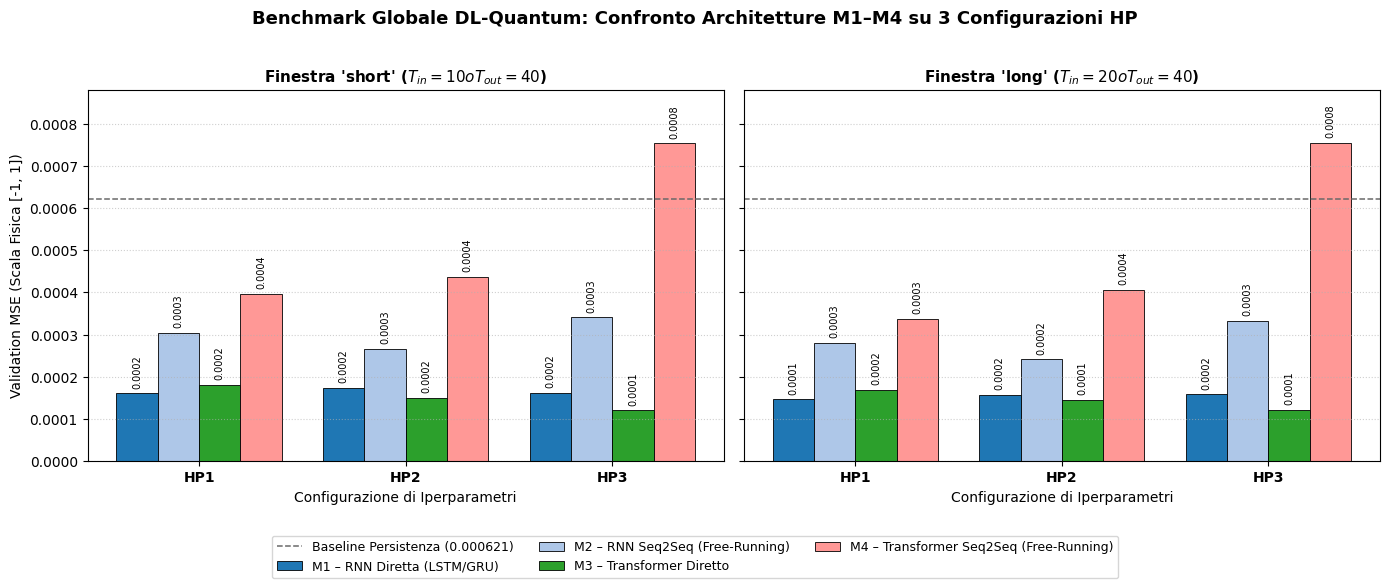

Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/05_inference/global_benchmark_summary.jpeg


In [5]:
# =============================================================================
# 2. Grafico Comparativo Globale (24 Configurazioni: M1, M2, M3, M4 x HP1..3)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

palette = {
    "M1_Direct": "#1f77b4",    # Blu: RNN Diretta
    "M2_Seq2Seq": "#aec7e8",   # Azzurro: RNN Seq2Seq
    "M3_Direct": "#2ca02c",    # Verde: Transformer Diretto
    "M4_Seq2Seq": "#ff9896",   # Rosa/Rosso: Transformer Seq2Seq
}
labels_map = {
    "M1_Direct": "M1 – RNN Diretta (LSTM/GRU)",
    "M2_Seq2Seq": "M2 – RNN Seq2Seq (Free-Running)",
    "M3_Direct": "M3 – Transformer Diretto",
    "M4_Seq2Seq": "M4 – Transformer Seq2Seq (Free-Running)",
}

hps = ["HP1", "HP2", "HP3"]
x = np.arange(len(hps))
width = 0.20

for ax_idx, (w_name, w_title) in enumerate([
    ("short", "Finestra 'short' ($T_{in} = 10 \to T_{out} = 40$)"),
    ("long", "Finestra 'long' ($T_{in} = 20 \to T_{out} = 40$)"),
]):
    ax = axes[ax_idx]
    sub_w = grid_df[grid_df["window"] == w_name]
    for m_idx, m_name in enumerate(model_order):
        sub_m = sub_w[sub_w["model_name"] == m_name].set_index("hp_name")
        vals = [float(sub_m.loc[hp, "val_mse"]) if hp in sub_m.index else 0.0 for hp in hps]
        bars = ax.bar(
            x + (m_idx - 1.5) * width,
            vals,
            width=width,
            color=palette[m_name],
            edgecolor="black",
            linewidth=0.6,
            label=labels_map[m_name] if ax_idx == 0 else None,
        )
        for bar, v in zip(bars, vals):
            if v > 0:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    v + 0.000012,
                    f"{v:.4f}",
                    ha="center",
                    va="bottom",
                    fontsize=7,
                    rotation=90,
                )

    ax.axhline(0.000621, color="dimgray", linestyle="--", lw=1.1, label="Baseline Persistenza (0.000621)" if ax_idx == 0 else None)
    ax.set_title(w_title, fontsize=11, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(hps, fontsize=10, fontweight="bold")
    ax.set_xlabel("Configurazione di Iperparametri")
    if ax_idx == 0:
        ax.set_ylabel("Validation MSE (Scala Fisica [-1, 1])")
    ax.set_ylim(0, 0.00088)
    ax.grid(axis="y", linestyle=":", alpha=0.6)

fig.suptitle("Benchmark Globale DL-Quantum: Confronto Architetture M1–M4 su 3 Configurazioni HP", fontsize=13, fontweight="bold", y=1.02)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=True, fontsize=9)
plt.tight_layout()

out_bench = save_figure(fig, "global_benchmark_summary.jpeg", subdir=FIG_SUBDIR)
plt.show()
print(f"Grafico esportato: {out_bench}")

## 2. Validazione Incrociata a 5 Fold per Traiettoria (`kfold_splits`, $k = 5$)

Per affiancare alla stabilità multi-seed una verifica di stabilità rispetto alla scelta delle traiettorie di training/validation, eseguiamo una **5-Fold Cross-Validation per traiettoria** sui due modelli vincitori su finestra `short`:
* **Campione RNN ($M_1$ `HP1`)**: LSTM 1 layer, 64 unità, dropout 0.0.
* **Campione Transformer ($M_3$ `HP3`)**: $d_{\text{model}}=64$, 2 teste, 1 layer, $d_{ff}=128$, dropout 0.0.

Le **60 traiettorie di Test** restano escluse; le **340 traiettorie di sviluppo** vengono divise in 5 fold disgiunti (272 train / 68 val per fold, IC 95% con $t_{0.975, 4} \approx 2.776$). I risultati vengono salvati in `results/kfold_cv_results.csv` per il caricamento istantaneo.

In [6]:
# =============================================================================
# 2. Esecuzione (o Caricamento Istantaneo da Cache) della 5-Fold Cross-Validation
# =============================================================================
kfold_csv_path = PATHS["results"] / "kfold_cv_results.csv"
FORCE_RECOMPUTE_KFOLD = False  # Imposta a True su Colab solo se vuoi ricalcolare da zero i 5 fold

if kfold_csv_path.exists() and not FORCE_RECOMPUTE_KFOLD:
    cv_df = pd.read_csv(kfold_csv_path)
    print(f"✔ Risultati 5-Fold Cross-Validation caricati istantaneamente da cache: {kfold_csv_path.name}")
else:
    cache_npy = PATHS["cache"] / "trajectories.npy"
    if cache_npy.exists() or PATHS["data_csv"].exists():
        print("Avvio 5-Fold Cross-Validation per traiettoria su 340 traiettorie di sviluppo (k=5)...")
        data_all = load_trajectories()
        split_dict = load_split()
        dev_indices = np.sort(np.concatenate([split_dict["train"], split_dict["val"]]))
        folds = kfold_splits(dev_indices, k=CFG["cv_folds"], seed=SEED)

        cv_records = []
        champions = [
            ("M1_Direct (RNN HP1)", "rnn_direct", make_config(model="rnn_direct", t_in=10, rnn_cell="lstm", rnn_units=64, rnn_layers=1, dropout=0.0)),
            ("M3_Direct (Transformer HP3)", "transformer_direct", make_config(model="transformer_direct", t_in=10, transformer_d_model=64, transformer_heads=2, transformer_d_ff=128, transformer_layers=1, dropout=0.0)),
        ]

        for label, fam, m_cfg in champions:
            print(f"\n--- 5-Fold CV per {label} ---")
            for fold_idx, (tr_idx, va_idx) in enumerate(folds, start=1):
                t0 = time.time()
                X_tr_f, Y_tr_f, meta_tr_f = make_windows(data_all, tr_idx, t_in=10, t_out=40, stride=10)
                X_va_f, Y_va_f, meta_va_f = make_windows(data_all, va_idx, t_in=10, t_out=40, stride=10)
                check_no_leakage({"train_fold": meta_tr_f, "val_fold": meta_va_f})

                set_seeds(SEED + fold_idx)
                if fam == "rnn_direct":
                    model_f = build_rnn_from_config(m_cfg, t_in=10)
                else:
                    model_f = build_transformer_from_config(m_cfg, t_in=10)

                _ = train_hybrid(model_f, X_tr_f, Y_tr_f, X_va_f, Y_va_f, m_cfg, seed=SEED + fold_idx, verbose=0)
                ev_f = evaluate(Y_va_f, predict(model_f, X_va_f), prefix="val_")
                elapsed = time.time() - t0
                print(f"  Fold {fold_idx}/5 | Val MSE: {ev_f['val_mse']:.6f} | Val MAE: {ev_f['val_mae']:.6f} ({elapsed:.1f}s)")

                cv_records.append({
                    "model_label": label,
                    "model_type": fam,
                    "fold": fold_idx,
                    "n_train_traj": len(tr_idx),
                    "n_val_traj": len(va_idx),
                    "val_mse": ev_f["val_mse"],
                    "val_mae": ev_f["val_mae"],
                    "val_rmse": ev_f["val_rmse"],
                    "val_mse_mag": ev_f["val_mse_mag"],
                    "val_mse_corr": ev_f["val_mse_corr"],
                    "time_s": round(elapsed, 1),
                })

        cv_df = pd.DataFrame(cv_records)
        cv_df.to_csv(kfold_csv_path, index=False)
        print(f"\n✔ 5-Fold Cross-Validation completata e salvata in: {kfold_csv_path}")
    else:
        print("ℹ Dataset trajectories.npy non presente in locale: apri questo notebook su Google Colab con Drive montato per eseguire i 5 fold (~10 min su GPU T4) e generare results/kfold_cv_results.csv.")
        cv_df = pd.DataFrame()

if not cv_df.empty:
    display(cv_df)
    print("\n" + "=" * 72)
    print("RIEPILOGO STATISTICO 5-FOLD CROSS-VALIDATION (t di Student, df=4, 95% CI):")
    for label, grp in cv_df.groupby("model_label", sort=False):
        print(
            f"  • {label:28s} | MSE: {format_mean_ci(grp['val_mse'], digits=6)} | "
            f"MAE: {format_mean_ci(grp['val_mae'], digits=6)}"
        )
    print("=" * 72)

Avvio 5-Fold Cross-Validation per traiettoria su 340 traiettorie di sviluppo (k=5)...

--- 5-Fold CV per M1_Direct (RNN HP1) ---
  Fold 1/5 | Val MSE: 0.000159 | Val MAE: 0.009083 (49.2s)
  Fold 2/5 | Val MSE: 0.000162 | Val MAE: 0.009155 (45.2s)
  Fold 3/5 | Val MSE: 0.000158 | Val MAE: 0.009027 (45.7s)
  Fold 4/5 | Val MSE: 0.000161 | Val MAE: 0.009124 (46.6s)
  Fold 5/5 | Val MSE: 0.000163 | Val MAE: 0.009187 (45.6s)

--- 5-Fold CV per M3_Direct (Transformer HP3) ---
  Fold 1/5 | Val MSE: 0.000120 | Val MAE: 0.007812 (71.7s)
  Fold 2/5 | Val MSE: 0.000122 | Val MAE: 0.007947 (70.7s)
  Fold 3/5 | Val MSE: 0.000118 | Val MAE: 0.007745 (71.5s)
  Fold 4/5 | Val MSE: 0.000119 | Val MAE: 0.007763 (71.2s)
  Fold 5/5 | Val MSE: 0.000120 | Val MAE: 0.007797 (71.4s)

✔ 5-Fold Cross-Validation completata e salvata in: /content/drive/MyDrive/DL-Quantum/results/kfold_cv_results.csv


,model_label,model_type,fold,n_train_traj,n_val_traj,val_mse,val_mae,val_rmse,val_mse_mag,val_mse_corr,time_s
0,M1_Direct (RNN HP1),rnn_direct,1,272,68,0.000159,0.009083,0.012625,0.000075,0.000178,49.2
1,M1_Direct (RNN HP1),rnn_direct,2,272,68,0.000162,0.009155,0.012709,0.000073,0.000181,45.2
2,M1_Direct (RNN HP1),rnn_direct,3,272,68,0.000158,0.009027,0.012568,0.000070,0.000178,45.7
3,M1_Direct (RNN HP1),rnn_direct,4,272,68,0.000161,0.009124,0.012674,0.000075,0.000180,46.6
4,M1_Direct (RNN HP1),rnn_direct,5,272,68,0.000163,0.009187,0.012766,0.000075,0.000182,45.6
5,M3_Direct (Transformer HP3),transformer_direct,1,272,68,0.000120,0.007812,0.010958,0.000035,0.000139,71.7
6,M3_Direct (Transformer HP3),transformer_direct,2,272,68,0.000122,0.007947,0.011060,0.000040,0.000141,70.7
7,M3_Direct (Transformer HP3),transformer_direct,3,272,68,0.000118,0.007745,0.010885,0.000035,0.000137,71.5
8,M3_Direct (Transformer HP3),transformer_direct,4,272,68,0.000119,0.007763,0.010902,0.000034,0.000138,71.2
9,M3_Direct (Transformer HP3),transformer_direct,5,272,68,0.000120,0.007797,0.010976,0.000035,0.000139,71.4



RIEPILOGO STATISTICO 5-FOLD CROSS-VALIDATION (t di Student, df=4, 95% CI):
  • M1_Direct (RNN HP1)          | MSE: 0.000160 ± 0.000002 | MAE: 0.009115 ± 0.000078
  • M3_Direct (Transformer HP3)  | MSE: 0.000120 ± 0.000002 | MAE: 0.007813 ± 0.000099


## 3. Confronto Unificato sulle Sfide Progettuali (RNN vs Transformer)

Confrontiamo direttamente i risultati salvati nei log per:
1. **Sfida 1 (Finestra Minima Ottima, $T_{in} \in \{5, 10, 20, 40\}$ con `align_t_in=40`)**: gomito comune a **`short` ($T_{in}=10$)** e vantaggio costante del $\sim 25\%$ di $M_3$ rispetto a $M_1$.
2. **Sfida 2 (Super-Risoluzione $\times 2$, $\Delta t = 0.04 \to 0.02\text{ s}$)**: ricostruzione dell'orizzonte futuro denso con scarto minimo ($+2.1\%$) rispetto all'input nativo.

=== SFIDA 1: CONFRONTO RNN (M1) vs TRANSFORMER (M3) SU TARGET ALLINEATI (Val & Test MSE) ===


<>:37: SyntaxWarning: invalid escape sequence '\D'
<>:54: SyntaxWarning: invalid escape sequence '\D'
<>:55: SyntaxWarning: invalid escape sequence '\D'
<>:37: SyntaxWarning: invalid escape sequence '\D'
<>:54: SyntaxWarning: invalid escape sequence '\D'
<>:55: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_1214/993978630.py:37: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel("Lunghezza Contesto Passato $T_{in}$ (passi, $\Delta t = 0.02$ s)")
/tmp/ipykernel_1214/993978630.py:54: SyntaxWarning: invalid escape sequence '\D'
  b1 = ax2.bar(x2 - w2 / 2, sr_vals, width=w2, color="#ff7f0e", edgecolor="black", lw=0.6, label="Super-Res $\times 2$ (20 pt, $\Delta t=0.04$s)")
/tmp/ipykernel_1214/993978630.py:55: SyntaxWarning: invalid escape sequence '\D'
  b2 = ax2.bar(x2 + w2 / 2, nat_vals, width=w2, color="#2ca02c", edgecolor="black", lw=0.6, label="Nativo Denso (39 pt, $\Delta t=0.02$s)")


val_mse            test_mse             val_mae            \
model_name M1_Direct M3_Direct M1_Direct M3_Direct M1_Direct M3_Direct   
t_in                                                                     
5           0.000171  0.000122  0.000172  0.000123  0.009454  0.007919   
10          0.000159  0.000122  0.000160  0.000122  0.009066  0.007860   
20          0.000147  0.000120  0.000148  0.000121  0.008628  0.007836   
40          0.000148  0.000111  0.000148  0.000111  0.008731  0.007578   

            test_mae            
model_name M1_Direct M3_Direct  
t_in                            
5           0.009491  0.007965  
10          0.009092  0.007888  
20          0.008654  0.007864  
40          0.008733  0.007573


=== SFIDA 2: SUPER-RISOLUZIONE TEMPORALE x2 (dt=0.04 -> dt=0.02) vs NATIVO DENSO ===


,model_name,window,t_in,val_mse,val_mae,test_mse,test_mae,val_mse_mag,val_mse_corr,train_time_s
0,M3_Direct_SR_x2,super_res_x2 (dt=0.04->0.02),20.0,0.000121,0.007844,0.000121,0.007881,0.000038,0.000139,73.9
1,M3_Direct_Native_dt002,native_dense (dt=0.02->0.02),39.0,0.000109,0.007529,0.000110,0.007539,0.000037,0.000125,79.5


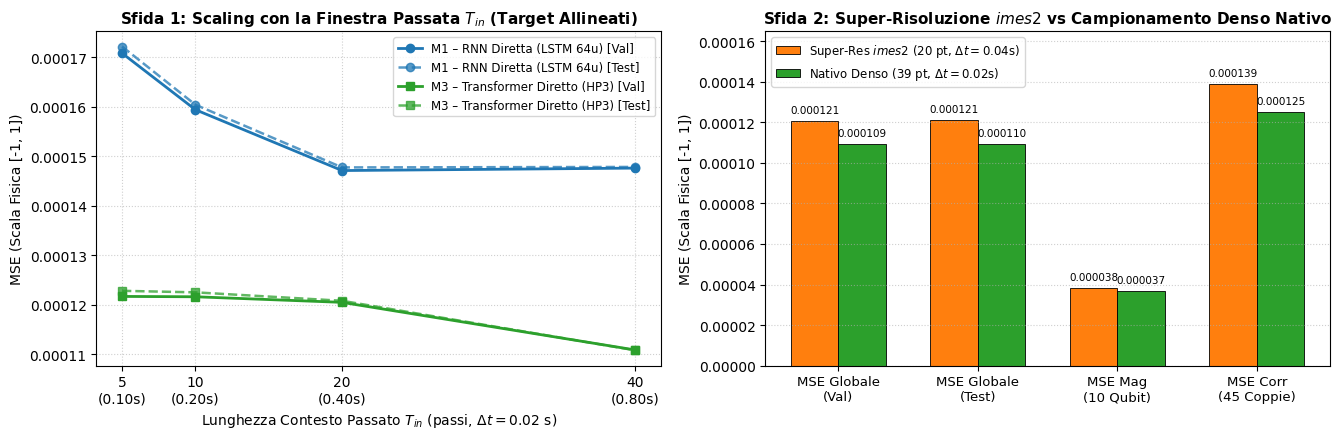

Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/05_inference/challenges_1_2_comparison.jpeg


In [7]:
# =============================================================================
# 3. Confronto Diretto Sfida 1 (Scaling Tin) e Sfida 2 (Super-Risoluzione)
# =============================================================================
sfida1_df = raw_logs[raw_logs["hp_name"].astype(str).str.startswith("Sfida1_Tin_")].copy()
sfida1_df["t_in"] = sfida1_df["t_in"].fillna(sfida1_df["T_in"]).astype(int)
sfida1_df = sfida1_df.sort_values("timestamp").drop_duplicates(
    subset=["model_name", "t_in"], keep="last"
).sort_values(["model_name", "t_in"]).reset_index(drop=True)

print("=== SFIDA 1: CONFRONTO RNN (M1) vs TRANSFORMER (M3) SU TARGET ALLINEATI (Val & Test MSE) ===")
piv_s1 = sfida1_df.pivot(index="t_in", columns="model_name", values=["val_mse", "test_mse", "val_mae", "test_mae"])
display(piv_s1)

sfida2_df = raw_logs[raw_logs["model_name"].isin(["M3_Direct_SR_x2", "M3_Direct_Native_dt002"])].copy()
sfida2_df = sfida2_df.sort_values("timestamp").drop_duplicates(subset=["model_name"], keep="last").reset_index(drop=True)

print("\n=== SFIDA 2: SUPER-RISOLUZIONE TEMPORALE x2 (dt=0.04 -> dt=0.02) vs NATIVO DENSO ===")
display(sfida2_df[[
    "model_name", "window", "t_in", "val_mse", "val_mae", "test_mse", "test_mae",
    "val_mse_mag", "val_mse_corr", "train_time_s"
]])

# Grafico combinato Sfida 1 (RNN vs Transformer) + Sfida 2 (Super-Resolution vs Nativo)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

# Pannello A: Sfida 1
ax = axes[0]
for m_name, color, marker, lbl in [
    ("M1_Direct", "#1f77b4", "o", "M1 – RNN Diretta (LSTM 64u)"),
    ("M3_Direct", "#2ca02c", "s", "M3 – Transformer Diretto (HP3)"),
]:
    sub = sfida1_df[sfida1_df["model_name"] == m_name].sort_values("t_in")
    ax.plot(sub["t_in"], sub["val_mse"], marker=marker, lw=2, color=color, label=f"{lbl} [Val]")
    ax.plot(sub["t_in"], sub["test_mse"], marker=marker, lw=1.8, ls="--", color=color, alpha=0.75, label=f"{lbl} [Test]")

ax.set_title("Sfida 1: Scaling con la Finestra Passata $T_{in}$ (Target Allineati)", fontsize=11, fontweight="bold")
ax.set_xlabel("Lunghezza Contesto Passato $T_{in}$ (passi, $\Delta t = 0.02$ s)")
ax.set_ylabel("MSE (Scala Fisica [-1, 1])")
ax.set_xticks([5, 10, 20, 40])
ax.set_xticklabels(["5\n(0.10s)", "10\n(0.20s)", "20\n(0.40s)", "40\n(0.80s)"])
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=8.5)

# Pannello B: Sfida 2
ax2 = axes[1]
if len(sfida2_df) == 2:
    sr_row = sfida2_df[sfida2_df["model_name"] == "M3_Direct_SR_x2"].iloc[0]
    nat_row = sfida2_df[sfida2_df["model_name"] == "M3_Direct_Native_dt002"].iloc[0]
    cats = ["MSE Globale\n(Val)", "MSE Globale\n(Test)", "MSE Mag\n(10 Qubit)", "MSE Corr\n(45 Coppie)"]
    sr_vals = [sr_row["val_mse"], sr_row["test_mse"], sr_row["val_mse_mag"], sr_row["val_mse_corr"]]
    nat_vals = [nat_row["val_mse"], nat_row["test_mse"], nat_row["val_mse_mag"], nat_row["val_mse_corr"]]
    x2 = np.arange(len(cats))
    w2 = 0.34
    b1 = ax2.bar(x2 - w2 / 2, sr_vals, width=w2, color="#ff7f0e", edgecolor="black", lw=0.6, label="Super-Res $\times 2$ (20 pt, $\Delta t=0.04$s)")
    b2 = ax2.bar(x2 + w2 / 2, nat_vals, width=w2, color="#2ca02c", edgecolor="black", lw=0.6, label="Nativo Denso (39 pt, $\Delta t=0.02$s)")
    for bars in (b1, b2):
        for bar in bars:
            h = bar.get_height()
            ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.000003, f"{h:.6f}", ha="center", va="bottom", fontsize=7.5)
    ax2.set_xticks(x2)
    ax2.set_xticklabels(cats, fontsize=9.5)
    ax2.set_ylim(0, 0.000165)
    ax2.set_ylabel("MSE (Scala Fisica [-1, 1])")
    ax2.set_title("Sfida 2: Super-Risoluzione $\times 2$ vs Campionamento Denso Nativo", fontsize=11, fontweight="bold")
    ax2.grid(axis="y", linestyle=":", alpha=0.6)
    ax2.legend(fontsize=8.5)

plt.tight_layout()
out_ch = save_figure(fig, "challenges_1_2_comparison.jpeg", subdir=FIG_SUBDIR)
plt.show()
print(f"Grafico esportato: {out_ch}")

## 4. Caricamento Checkpoint `.keras` e Demo di Inferenza Live sul Test Set (Esame Orale)

Cella pensata per la **dimostrazione live all'orale (< 1 secondo, nessun retraining)**:
1. Ricarica i checkpoint `checkpoints/best_rnn_model.keras` ($M_1$) e `checkpoints/best_transformer_model.keras` ($M_3$) con `ALL_CUSTOM_OBJECTS`.
2. Valuta entrambi i modelli sulle **60 traiettorie del Test Set Cieco** ($5.760$ finestre `short`) e verifica la positività quantistica $P(s_i, s_j) \ge 0$.
3. Plotta il confronto diretto **Ground Truth vs RNN ($M_1$) vs Transformer ($M_3$)** su una finestra di test a scelta (`DEMO_WINDOW_IDX`).

<>:75: SyntaxWarning: invalid escape sequence '\D'
<>:75: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_1214/2063823745.py:75: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel("Tempo relativo $\Delta t$ (s)")


✔ Inferenza completa su 5760 finestre del Test Set Cieco eseguita in 1.72 s!



,Modello,Test MSE,Test MAE,Test RMSE,Test MSE Mag,Test MSE Corr,"Min P(s_i, s_j)",Violazioni Fisiche (%)
0,M1_Direct (Best RNN - HP1),0.000161,0.009112,0.012702,0.000072,0.000181,0.167240,0.0
1,M3_Direct (Best Transformer - HP3),0.000121,0.007850,0.011003,0.000036,0.000140,0.163186,0.0


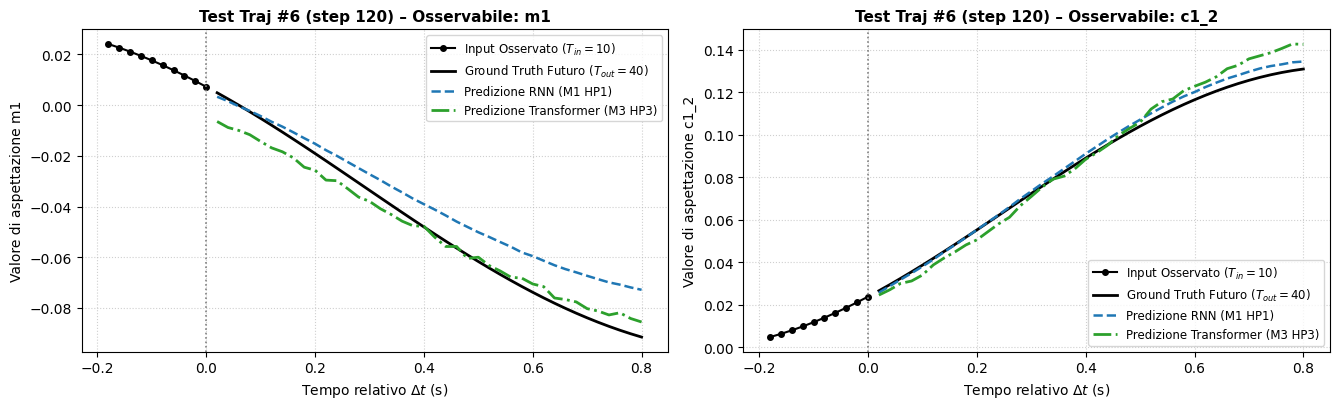

Grafico Demo Test Set esportato: /content/drive/MyDrive/DL-Quantum/figures/05_inference/test_set_live_prediction.jpeg


In [10]:
# =============================================================================
# 4. Caricamento Modelli Salvati (.keras), Valutazione Test Set e Demo Live Orale
# =============================================================================
rnn_ckpt = PATHS["checkpoints"] / "best_rnn_model.keras"
trf_ckpt = PATHS["checkpoints"] / "best_transformer_model.keras"
cache_npy = PATHS["cache"] / "trajectories.npy"

# Indice della finestra del Test Set da visualizzare durante la demo orale (0 .. 5759)
DEMO_WINDOW_IDX = 12
DEMO_FEATURES = [0, 10]  # 0 -> m1 (<sigma_z^1>), 10 -> c1_2 (<sigma_z^1 sigma_z^2>)

if (cache_npy.exists() or PATHS["data_csv"].exists()) and rnn_ckpt.exists() and trf_ckpt.exists():
    t0 = time.time()
    data_all = load_trajectories()
    split_dict = load_split()
    X_te, Y_te, meta_te = make_windows(data_all, split_dict["test"], t_in=10, t_out=40, stride=10)

    best_rnn = keras.models.load_model(rnn_ckpt, custom_objects=ALL_CUSTOM_OBJECTS)
    best_trf = keras.models.load_model(trf_ckpt, custom_objects=ALL_CUSTOM_OBJECTS)

    Y_pred_rnn = predict(best_rnn, X_te)
    Y_pred_trf = predict(best_trf, X_te)
    infer_time = time.time() - t0

    ev_rnn_test = evaluate(Y_te, Y_pred_rnn, prefix="test_")
    ev_trf_test = evaluate(Y_te, Y_pred_trf, prefix="test_")
    phys_rnn = check_quantum_probabilities(Y_pred_rnn)
    phys_trf = check_quantum_probabilities(Y_pred_trf)

    print(f"✔ Inferenza completa su {len(X_te)} finestre del Test Set Cieco eseguita in {infer_time:.2f} s!\n")
    test_summary_df = pd.DataFrame([
        {
            "Modello": "M1_Direct (Best RNN - HP1)",
            "Test MSE": ev_rnn_test["test_mse"],
            "Test MAE": ev_rnn_test["test_mae"],
            "Test RMSE": ev_rnn_test["test_rmse"],
            "Test MSE Mag": ev_rnn_test["test_mse_mag"],
            "Test MSE Corr": ev_rnn_test["test_mse_corr"],
            "Min P(s_i, s_j)": phys_rnn["min_probability"],
            "Violazioni Fisiche (%)": phys_rnn["violation_rate"] * 100.0,
        },
        {
            "Modello": "M3_Direct (Best Transformer - HP3)",
            "Test MSE": ev_trf_test["test_mse"],
            "Test MAE": ev_trf_test["test_mae"],
            "Test RMSE": ev_trf_test["test_rmse"],
            "Test MSE Mag": ev_trf_test["test_mse_mag"],
            "Test MSE Corr": ev_trf_test["test_mse_corr"],
            "Min P(s_i, s_j)": phys_trf["min_probability"],
            "Violazioni Fisiche (%)": phys_trf["violation_rate"] * 100.0,
        },
    ])
    display(test_summary_df)

    # Grafico Demo Live su una singola finestra del Test Set
    names = feature_names()
    x_win = X_te[DEMO_WINDOW_IDX]
    y_win = Y_te[DEMO_WINDOW_IDX]
    p_rnn_win = Y_pred_rnn[DEMO_WINDOW_IDX]
    p_trf_win = Y_pred_trf[DEMO_WINDOW_IDX]
    traj_id, start_step = meta_te[DEMO_WINDOW_IDX]

    t_past = np.arange(-len(x_win) + 1, 1) * DT
    t_fut = np.arange(1, len(y_win) + 1) * DT

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
    for idx_ax, f_idx in enumerate(DEMO_FEATURES):
        ax = axes[idx_ax]
        ax.plot(t_past, x_win[:, f_idx], "ko-", ms=4, lw=1.5, label="Input Osservato ($T_{in}=10$)")
        ax.plot(t_fut, y_win[:, f_idx], "k-", lw=2.0, label="Ground Truth Futuro ($T_{out}=40$)")
        ax.plot(t_fut, p_rnn_win[:, f_idx], "--", color="#1f77b4", lw=1.8, label="Predizione RNN (M1 HP1)")
        ax.plot(t_fut, p_trf_win[:, f_idx], "-.", color="#2ca02c", lw=2.0, label="Predizione Transformer (M3 HP3)")
        ax.axvline(0.0, color="gray", linestyle=":", lw=1.2)
        ax.set_title(f"Test Traj #{traj_id} (step {start_step}) – Osservabile: {names[f_idx]}", fontsize=11, fontweight="bold")
        ax.set_xlabel("Tempo relativo $\Delta t$ (s)")
        ax.set_ylabel(f"Valore di aspettazione {names[f_idx]}")
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.legend(fontsize=8.5)

    plt.tight_layout()
    out_demo = save_figure(fig, "test_set_live_prediction.jpeg", subdir=FIG_SUBDIR)
    plt.show()
    print(f"Grafico Demo Test Set esportato: {out_demo}")
else:
    print("ℹ Per eseguire l'inferenza live dai checkpoint .keras sul Test Set completo, apri questo notebook su Google Colab (con Google Drive montato).")
    print("  I risultati numerici di Test Set gia' registrati nei log per la finestra allineata (Tin=10) sono:")
    s1_t10 = sfida1_df[sfida1_df["t_in"] == 10][["model_name", "val_mse", "val_mae", "test_mse", "test_mae"]]
    display(s1_t10)

## 5. Sincronizzazione e Push su GitHub

Salvataggio automatico delle tabelle (`results/table1_*.csv`, `results/kfold_cv_results.csv`), delle figure in `figures/05_inference/` e push sul branch dell'autore attivo.

In [9]:
# =============================================================================
# Sincronizzazione dei Risultati e Push su GitHub (Multi-Utente)
# =============================================================================
import os
from pathlib import Path

target_repo = Path("/content/drive/MyDrive/DL-Quantum") if Path("/content/drive/MyDrive/DL-Quantum").exists() else REPO_PATH

print(f"--- SINCRONIZZAZIONE SUL BRANCH: {CURRENT_BRANCH} (Autore: {AUTHOR_NAME}) ---")

!git -C "{target_repo}" config user.name "{AUTHOR_NAME}"
!git -C "{target_repo}" config user.email "{AUTHOR_EMAIL}"

!git -C "{target_repo}" fetch origin
!git -C "{target_repo}" pull --rebase --autostash origin {CURRENT_BRANCH}

!git -C "{target_repo}" add results/ figures/ notebooks/ src/ README.md
commit_msg = f"feat: benchmark finale Table 1 e pipeline inferenza [{CURRENT_BRANCH}] di {AUTHOR_NAME}"
!git -C "{target_repo}" commit -m "{commit_msg}"
!git -C "{target_repo}" status -s

if GIT_TOKEN:
    print(f"\nPush automatico in corso sul branch '{CURRENT_BRANCH}' con token di {AUTHOR_NAME}...")
    push_out = !git -C "{target_repo}" push https://{GIT_TOKEN}@github.com/Riccardo-27/DL-Quantum.git {CURRENT_BRANCH}
    print("\n".join(push_out))
    push_err = any("rejected" in l.lower() or "error:" in l.lower() or "fatal:" in l.lower() for l in push_out)
    if push_err:
        print(f"\n[ATTENZIONE] Il push è stato respinto. Risolvi eventuali divergenze con '!git -C \"{target_repo}\" pull --rebase --autostash origin {CURRENT_BRANCH}' e riprova.")
    else:
        print(f"\n✔ Sincronizzazione completata con successo su '{CURRENT_BRANCH}'!")
else:
    if IN_COLAB:
        print("\n[ATTENZIONE] Nessun token rilevato per il push automatico su Colab.")
    else:
        print(f"\nAmbiente locale: per il push esegui 'git push origin {CURRENT_BRANCH}' da terminale.")

--- SINCRONIZZAZIONE SUL BRANCH: dev-ernesto (Autore: Ernesto Gligora) ---
From https://github.com/Riccardo-27/DL-Quantum
 * branch            dev-ernesto -> FETCH_HEAD
Already up to date.
[dev-ernesto da1159a] feat: benchmark finale Table 1 e pipeline inferenza [dev-ernesto] di Ernesto Gligora
 4 files changed, 11 insertions(+)
 create mode 100644 figures/05_inference/test_set_live_prediction.jpeg
 create mode 100644 results/kfold_cv_results.csv

Push automatico in corso sul branch 'dev-ernesto' con token di Ernesto Gligora...
Enumerating objects: 15, done.
Counting objects:   6% (1/15)
Counting objects:  13% (2/15)
Counting objects:  20% (3/15)
Counting objects:  26% (4/15)
Counting objects:  33% (5/15)
Counting objects:  40% (6/15)
Counting objects:  46% (7/15)
Counting objects:  53% (8/15)
Counting objects:  60% (9/15)
Counting objects:  66% (10/15)
Counting objects:  73% (11/15)
Counting objects:  80% (12/15)
Counting objects:  86% (13/15)
Counting objects:  93% (14/15)
Counting o